In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage import io, filters, color, img_as_float
from skimage.morphology import skeletonize, thin

BASE = '/content/drive/MyDrive/PCVK/Gambar'
PLAT = os.path.join(BASE, 'plat_nomer.png')
KITTEN = os.path.join(BASE, 'kitten01.jpg')
LILY = os.path.join(BASE, 'lily.jpg')
J_IMAGE = os.path.join(BASE, 'j.png')

def baca_citra(path, grayscale=True):
    citra = cv2.imread(path, cv2.IMREAD_GRAYSCALE if grayscale else cv2.IMREAD_COLOR)
    if citra is None:
        raise FileNotFoundError(f'File tidak ditemukan: {path}. Periksa nama dan lokasi file di Google Drive.')
    return citra

def tampilkan(*items, figsize=None):
    # items berupa pasangan (judul, citra, cmap)
    if figsize is None:
        figsize = (5 * len(items), 4)
    plt.figure(figsize=figsize)
    for i, item in enumerate(items, 1):
        judul, citra = item[0], item[1]
        cmap = item[2] if len(item) > 2 else 'gray'
        plt.subplot(1, len(items), i)
        plt.imshow(citra, cmap=cmap)
        plt.title(judul)
        plt.xticks([]); plt.yticks([])
    plt.tight_layout()
    plt.show()

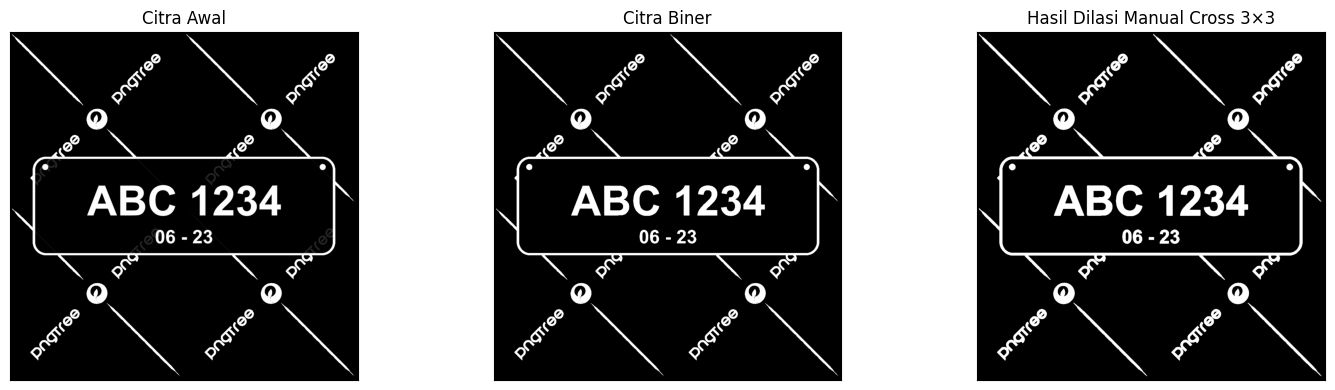

In [16]:
def dilasi_manual(F, SE):
    F = (F > 0).astype(np.uint8) * 255
    SE = (SE > 0).astype(np.uint8)
    h, w = F.shape
    kh, kw = SE.shape
    ph, pw = kh // 2, kw // 2
    padded = cv2.copyMakeBorder(F, ph, ph, pw, pw, cv2.BORDER_CONSTANT, value=0)
    hasil = np.zeros_like(F)
    for i in range(h):
        for j in range(w):
            area = padded[i:i+kh, j:j+kw]
            if np.any(area[SE == 1] > 0):
                hasil[i, j] = 255
    return hasil

img = baca_citra(PLAT)
_, biner = cv2.threshold(img, 125, 255, cv2.THRESH_BINARY)
SE_CROSS3 = np.array([[0,1,0],[1,1,1],[0,1,0]], dtype=np.uint8)
hasil_dilasi_manual = dilasi_manual(biner, SE_CROSS3)
tampilkan(('Citra Awal', img), ('Citra Biner', biner), ('Hasil Dilasi Manual Cross 3×3', hasil_dilasi_manual))